# 6. Experimento 5 – Vieses, atributos sensíveis e explicabilidade

**Projeto:** Agente Identificador de Fraudes Bancárias  
**Disciplina:** Inteligência Artificial – 7º semestre – Ciência da Computação  
**Instituição:** Universidade Presbiteriana Mackenzie – Faculdade de Computação e Informática  
**Professor:** Prof. Dr. Ivan Carlos Alcântara de Oliveira

| Integrante | RA | E-mail |
|---|---|---|
| Cheuk Ki Yu | 10419664 | cheuk.yu@mackenzista.com.br |
| Gabriela Nellessen de Sousa | 10441930 | gabrielanellessen@gmail.com |
| Milton Almeida Leoncio | 10416764 | milton.almeida@live.com |

**Síntese:** Recall e taxa de falsos positivos por grupo (gênero, faixa etária, renda), comparação com e sem atributos sensíveis, importância global e explicações locais.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-11-20 | Milton Almeida Leoncio | Versão final do projeto (N2) |

In [1]:
# ========================================================================================
# Projeto: Agente Identificador de Fraudes Bancárias
# Disciplina: Inteligência Artificial - 7º semestre - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática (FCI)
# Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrantes:
#   Cheuk Ki Yu                  - RA 10419664 - cheuk.yu@mackenzista.com.br
#   Gabriela Nellessen de Sousa  - RA 10441930 - gabrielanellessen@gmail.com
#   Milton Almeida Leoncio       - RA 10416764 - milton.almeida@live.com
# Arquivo: notebooks/06_etica_explicabilidade.ipynb
# Síntese: Recall e taxa de falsos positivos por grupo (gênero, faixa etária, renda), comparação com e sem atributos sensíveis, importância global e explicações locais.
# Histórico de alterações:
#   2026-11-20 - Milton Almeida Leoncio - Versão final do projeto (N2)
# ========================================================================================

import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
os.environ.setdefault('FRAUDES_ATRIBUTOS', str(RAIZ / 'atributos'))  # saída de preparar_bases.py
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = RAIZ / 'resultados'

## 6.1 Desempenho com e sem atributos sensíveis

In [2]:
import exp5_etica_xai as e5
res = {k: e5.executar(k) for k in ('A', 'B')}
cols = ['modelo', 'final', 'n_atributos', 'val_pr_auc', 'precision', 'recall', 'f1', 'pr_auc', 'dif_f1_vs_final', 'dif_f1_ic_inf', 'dif_f1_ic_sup']
for k in ('A', 'B'):
    print(k); display(res[k]['resumo'][[x for x in cols if x in res[k]['resumo']]])

A


,modelo,final,n_atributos,val_pr_auc,precision,recall,f1,pr_auc,dif_f1_vs_final,dif_f1_ic_inf,dif_f1_ic_sup
0,Sem atributos sensíveis,True,29,0.728,0.712,0.671,0.691,0.759,NaN,NaN,NaN
1,Com atributos sensíveis,False,35,0.684,0.640,0.583,0.610,0.646,-0.081,-0.098,-0.065


B


,modelo,final,n_atributos,val_pr_auc,precision,recall,f1,pr_auc,dif_f1_vs_final,dif_f1_ic_inf,dif_f1_ic_sup
0,Com atributos sensíveis,True,14,0.950,0.871,0.830,0.850,0.912,NaN,NaN,NaN
1,Sem atributos sensíveis,False,13,0.930,0.884,0.760,0.818,0.879,-0.033,-0.064,-0.003


## 6.2 Métricas por grupo e disparidades

In [3]:
display(res['A']['disparidades'])
display(res['B']['disparidades'])
res['A']['grupos']

,modelo,atributo,dif_recall_max_min,fpr_10k_min,fpr_10k_max,dif_fpr_10k_max_min,razao_fpr_max_min
0,Com atributos sensíveis,Faixa etária,0.137,3.310,4.270,0.960,1.290
1,Com atributos sensíveis,Gênero,0.021,3.190,4.710,1.520,1.476
2,Com atributos sensíveis,Quartil de renda,0.377,3.440,4.810,1.370,1.398
3,Sem atributos sensíveis,Faixa etária,0.063,2.590,3.680,1.090,1.421
4,Sem atributos sensíveis,Gênero,0.010,2.510,4.010,1.500,1.598
5,Sem atributos sensíveis,Quartil de renda,0.167,2.080,4.140,2.060,1.990


,modelo,atributo,dif_recall_max_min,fpr_10k_min,fpr_10k_max,dif_fpr_10k_max_min,razao_fpr_max_min
0,Com atributos sensíveis,Faixa etária,0.333,0.000,6.530,6.530,NaN
1,Sem atributos sensíveis,Faixa etária,0.341,0.000,4.350,4.350,NaN


,atributo,grupo,n,fraudes,recall,fpr,precision,alertas_10k,modelo
0,Faixa etária,30-44,516869,505,0.640,0.000,0.630,9.925,Sem atributos sensíveis
1,Faixa etária,45-59,600197,667,0.688,0.000,0.748,10.230,Sem atributos sensíveis
2,Faixa etária,60 ou mais,497977,875,0.678,0.000,0.767,15.523,Sem atributos sensíveis
3,Faixa etária,< 30,108895,40,0.625,0.000,0.385,5.969,Sem atributos sensíveis
4,Gênero,Feminino,888899,1100,0.675,0.000,0.676,12.364,Sem atributos sensíveis
5,Gênero,Masculino,835039,987,0.666,0.000,0.759,10.371,Sem atributos sensíveis
6,Quartil de renda,Q1 (menor),401789,564,0.715,0.000,0.746,13.440,Sem atributos sensíveis
7,Quartil de renda,Q2,404263,481,0.705,0.000,0.801,10.463,Sem atributos sensíveis
8,Quartil de renda,Q3,440947,509,0.717,0.000,0.713,11.611,Sem atributos sensíveis
9,Quartil de renda,Q4 (maior),476939,533,0.550,0.000,0.598,10.274,Sem atributos sensíveis


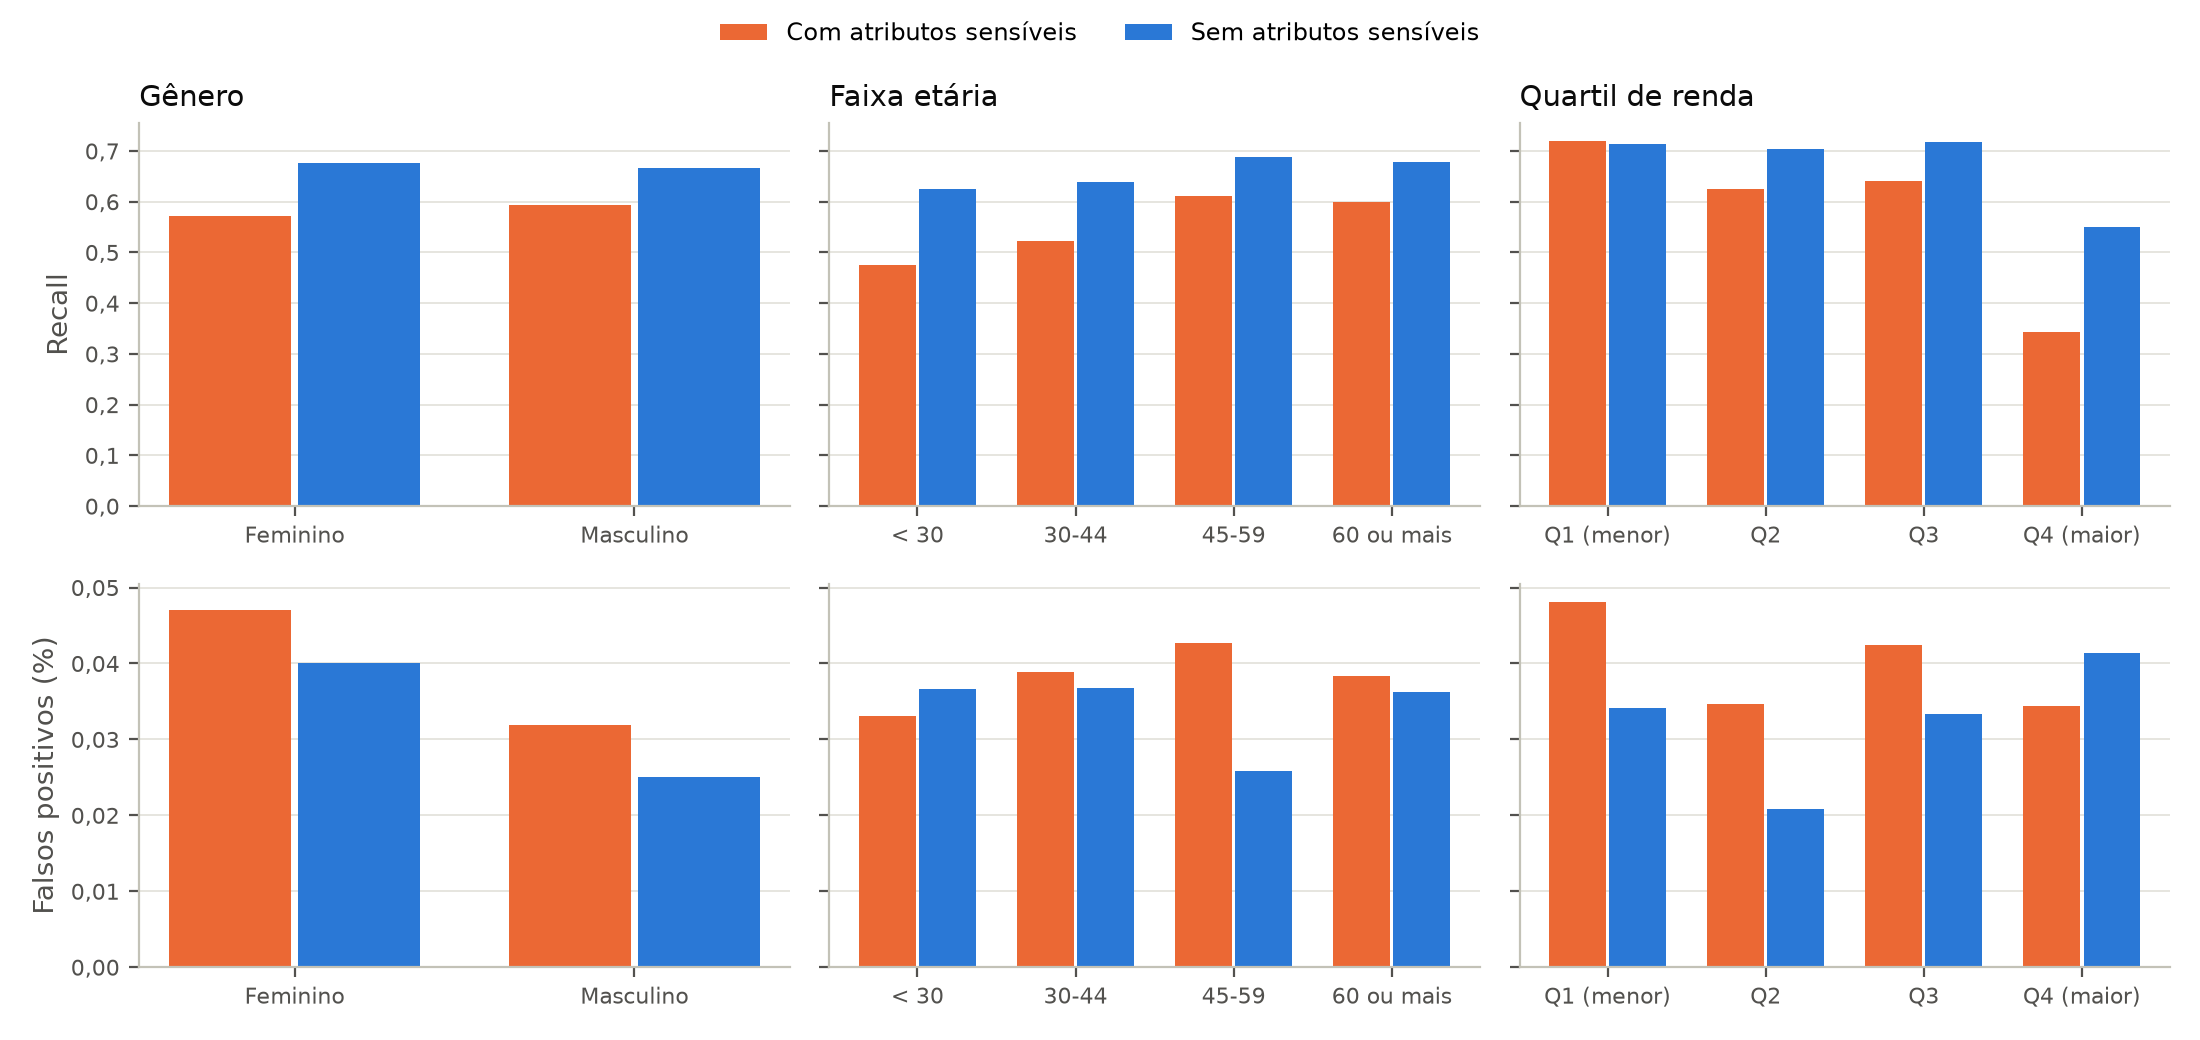

In [4]:
e5.figuras()
display(Image(FIG / 'fig_exp5_grupos_A.png', width=1000))

**Leitura dos resultados.** Na Base A, o modelo final (sem atributos sensíveis) é mais preciso e reduz as diferenças de recall entre grupos. Ainda assim, o quartil de maior renda tem recall menor. Na Base B, retirar a idade custa cerca de 0,03 de F1 sem reduzir a disparidade entre faixas, que têm poucas fraudes no teste.

## 6.3 Explicabilidade

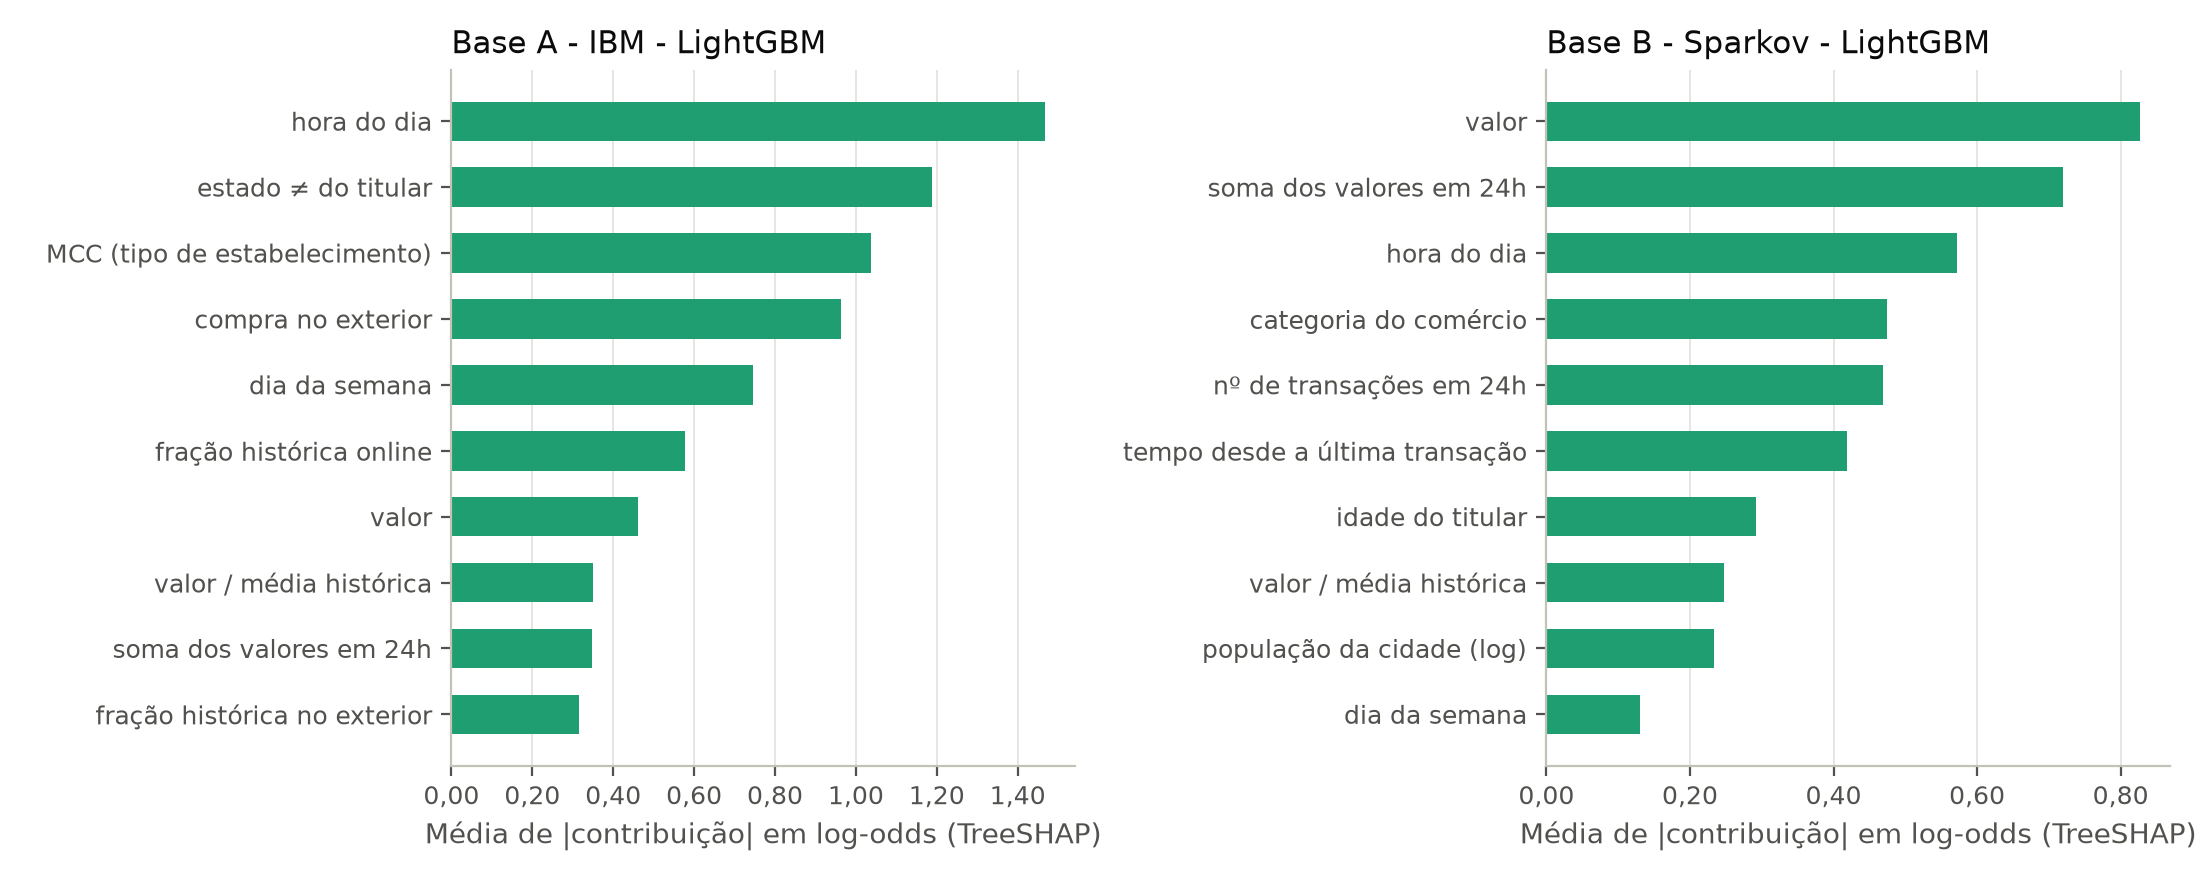

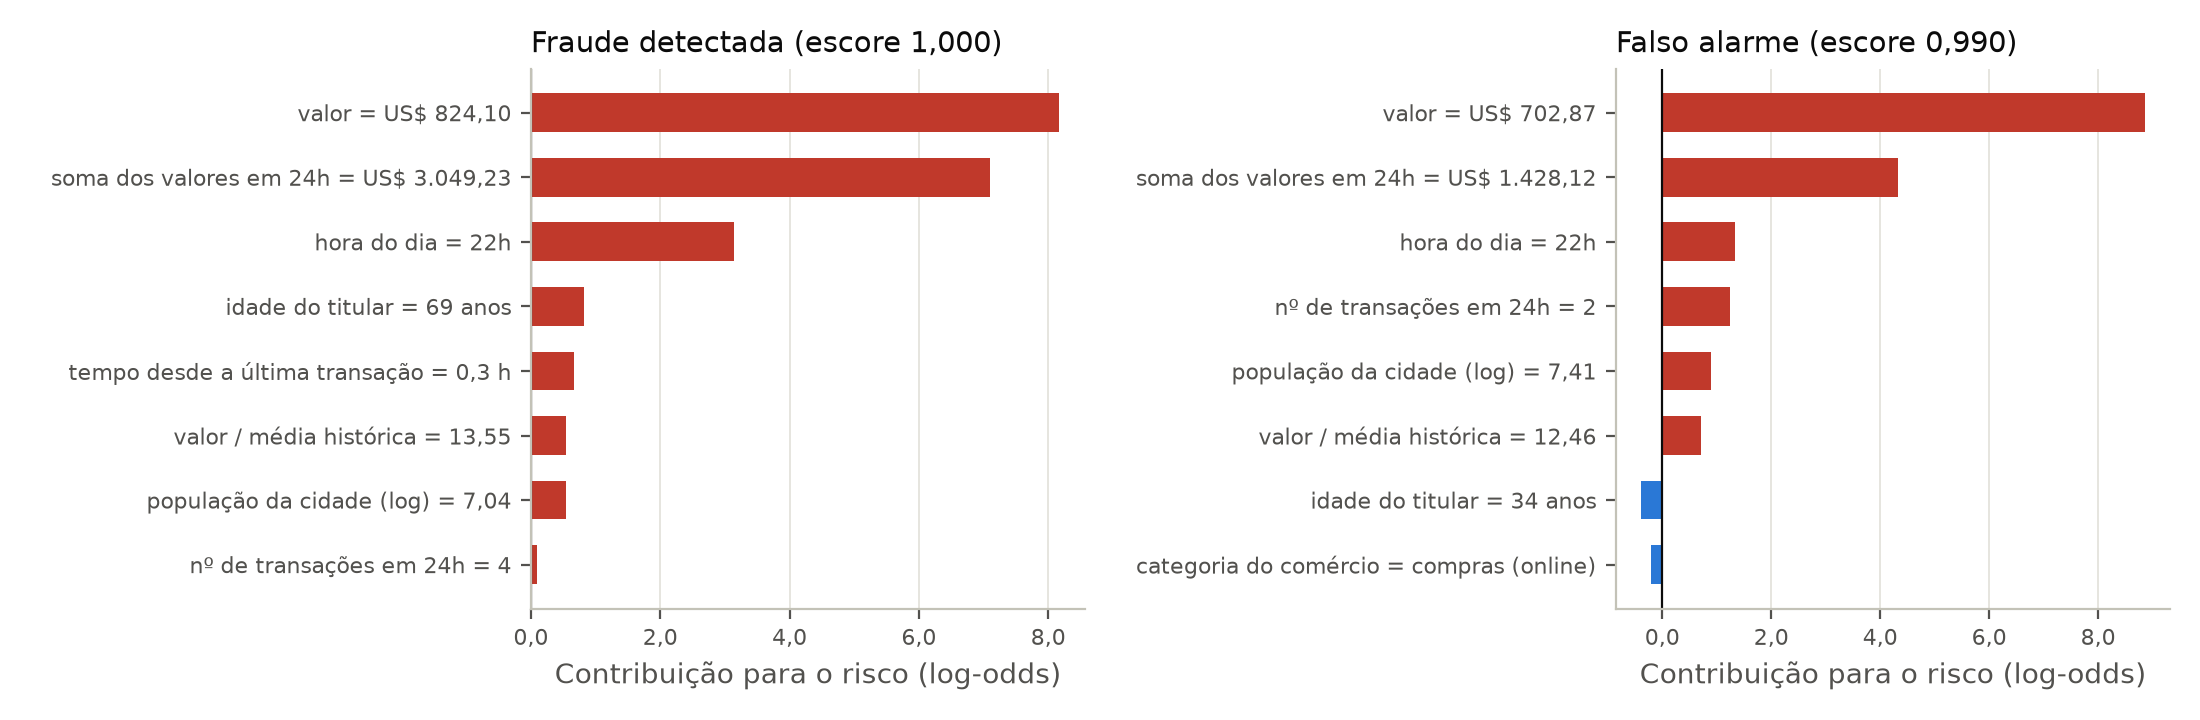

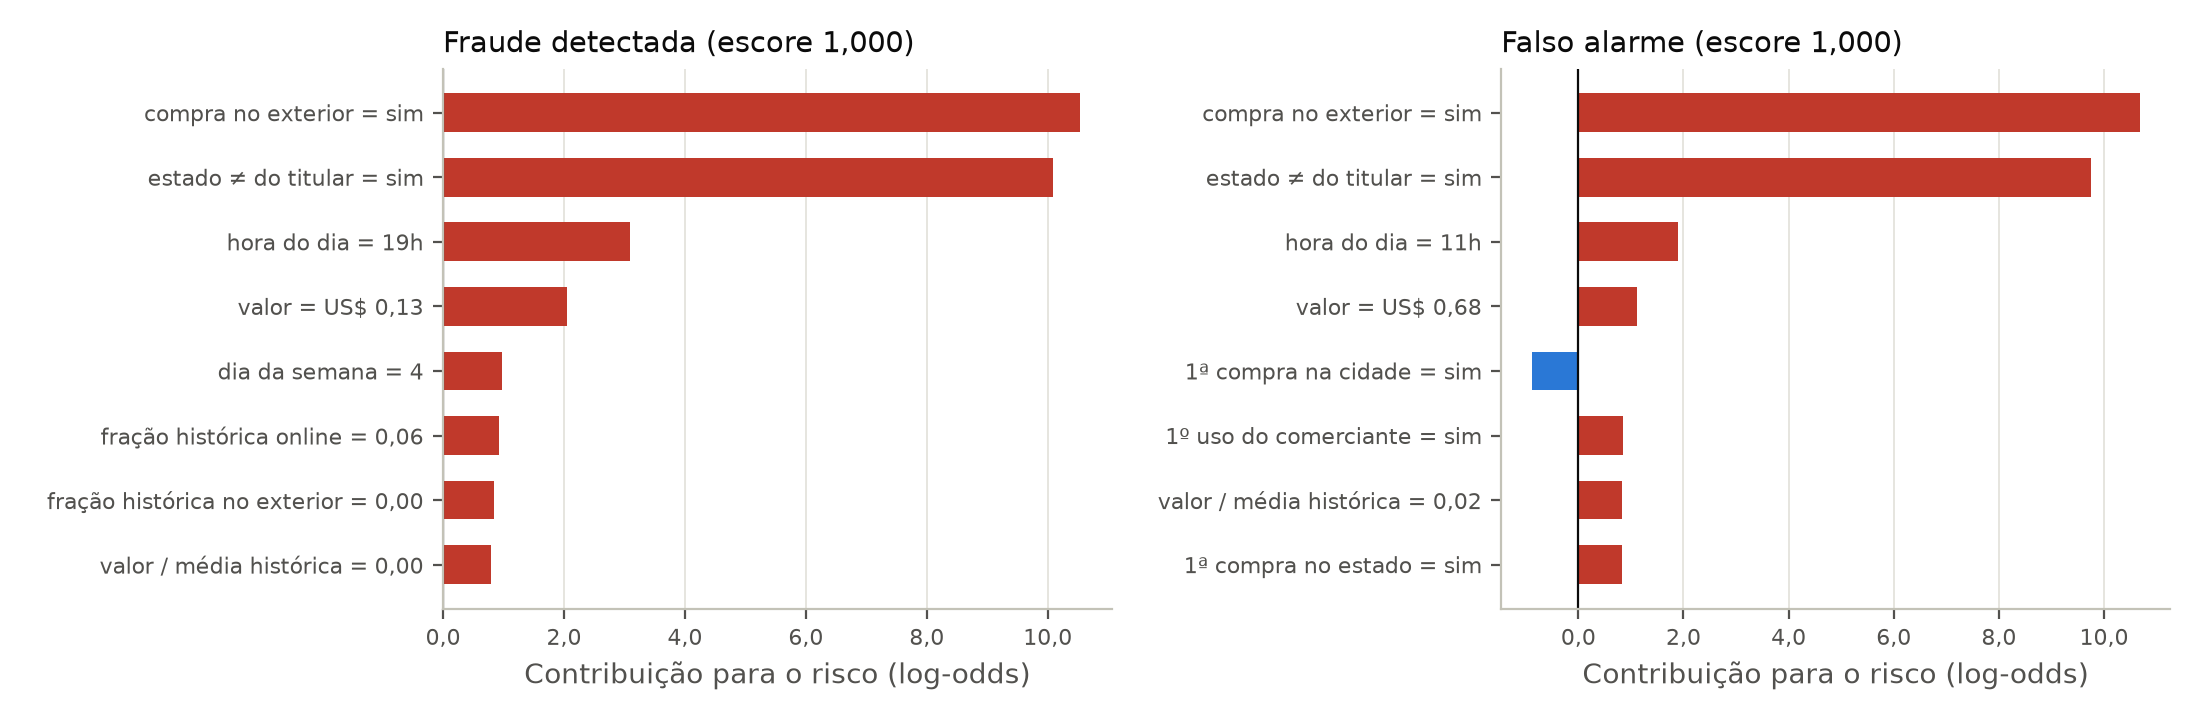

In [5]:
display(Image(FIG / 'fig_exp5_importancia_global.png', width=1000))
for k in ('B', 'A'):
    display(Image(FIG / f'fig_exp5_local_{k}.png', width=1000))